# Physical Activity and the Depressive-Symptom Network among U.S. Adults
### NHANES 2017 – March 2020 · Pair Project Proposal — verification notebook

**Course:** CISC7204 Data Science and Data Visualization — Assignment 02, Pair Project Proposal
**Pair:** ZHU ZHONGXIN (MC662722) · DENG YI (MC662921) · Class K

**Research question.** *Among U.S. adults, how is habitual physical activity related to the level and the
structure of depressive symptoms measured by the PHQ-9 — and does the symptom network of physically active
adults differ from that of inactive adults?*

The notebook runs the full pipeline (import, wrangling, descriptive statistics, exploratory visualisation,
group comparisons, an adjusted logistic regression with a forest plot, a dose–response analysis and an
age-stratified check) and then the network layer: a partial-correlation network of the nine PHQ-9 symptoms,
its centrality indices, and a permutation test comparing overall network connectivity between physically
active and inactive adults. Eleven figures and every number quoted in the proposal are produced here.

## 0. Setup

In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import networkx as nx

pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid', context='notebook')
rng = np.random.default_rng(42)

DATA, FIG = 'data', 'figures'
os.makedirs(FIG, exist_ok=True)

ITEMS  = ['DPQ010','DPQ020','DPQ030','DPQ040','DPQ050','DPQ060','DPQ070','DPQ080','DPQ090']
LABELS = {'DPQ010':'Anhedonia','DPQ020':'Sad mood','DPQ030':'Sleep','DPQ040':'Fatigue',
          'DPQ050':'Appetite','DPQ060':'Self-worth','DPQ070':'Concentration',
          'DPQ080':'Psychomotor','DPQ090':'Self-harm'}
SHORT  = [LABELS[i] for i in ITEMS]
print('pandas', pd.__version__, '| numpy', np.__version__, '| networkx', nx.__version__)

pandas 3.0.3 | numpy 2.4.6 | networkx 3.6.1


## 1. Import and merge the NHANES files
Four public-use files are joined on the respondent ID (`SEQN`): Depression (DPQ), Demographics (DEMO),
Body Measures (BMX) and Physical Activity (PAQ), NHANES 2017 – March 2020 cycle. From PAQ the notebook
keeps both the **occupational** items (PAQ605 vigorous and PAQ620 moderate work activity) and the
**leisure-time** items (PAQ650 vigorous and PAQ665 moderate recreational activity), so that the two kinds
of "physical activity" can be told apart. The official SAS-XPORT (.xpt) files were converted to CSV; the
notebook reads the CSV copies.

In [2]:
dpq  = pd.read_csv(os.path.join(DATA,'DPQ_J.csv'))
demo = pd.read_csv(os.path.join(DATA,'DEMO_J.csv'))
bmx  = pd.read_csv(os.path.join(DATA,'BMX_J.csv'))
paq  = pd.read_csv(os.path.join(DATA,'PAQ_J.csv'))

df = (dpq[['SEQN']+ITEMS]
      .merge(demo[['SEQN','RIAGENDR','RIDAGEYR']], on='SEQN', how='inner')
      .merge(bmx[['SEQN','BMXBMI']],              on='SEQN', how='inner')
      .merge(paq[['SEQN','PAQ605','PAQ620','PAQ650','PAQ665']], on='SEQN', how='inner'))
print('merged rows:', len(df))
df.head(3)

merged rows: 5533


,SEQN,DPQ010,DPQ020,DPQ030,DPQ040,DPQ050,DPQ060,DPQ070,DPQ080,DPQ090,RIAGENDR,RIDAGEYR,BMXBMI,PAQ605,PAQ620,PAQ650,PAQ665
0,93705.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,2.0,66.0,31.7,2.0,2.0,2.0,1.0
1,93706.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,1.0,18.0,21.5,2.0,2.0,2.0,1.0
2,93708.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,2.0,66.0,23.7,2.0,2.0,2.0,1.0


## 2. Data wrangling
Adults aged 20–80; sex recoded; physical activity derived at two granularities — a binary flag (any
vigorous **or** moderate leisure-time activity) and a four-level intensity variable (none / moderate only /
vigorous only / both); occupational activity kept as a separate flag; PHQ-9 total with the standard
severity bands; BMI categories. Refused/don't-know codes (7, 9) fall out as missing.

In [3]:
df = df[(df['RIDAGEYR']>=20) & (df['RIDAGEYR']<=80)].copy()
df['Sex'] = df['RIAGENDR'].map({1:'Male',2:'Female'})

# leisure-time (recreational) activity: PAQ650 vigorous, PAQ665 moderate
vig_rec, mod_rec = df['PAQ650'].isin([1]), df['PAQ665'].isin([1])
no_rec           = df['PAQ650'].isin([2]) & df['PAQ665'].isin([2])
df['Active'] = np.select([vig_rec|mod_rec, no_rec], ['Active','Inactive'], default='')
df['Active'] = df['Active'].replace('', np.nan)

df['PA_level'] = np.select(
    [no_rec, mod_rec & ~vig_rec, vig_rec & ~mod_rec, vig_rec & mod_rec],
    ['None','Moderate only','Vigorous only','Both'], default='')
df['PA_level'] = df['PA_level'].replace('', np.nan)

# occupational activity: PAQ605 vigorous work, PAQ620 moderate work
work = df['PAQ605'].isin([1]) | df['PAQ620'].isin([1])
work_no = df['PAQ605'].isin([2]) & df['PAQ620'].isin([2])
df['Work'] = np.select([work, work_no], ['Yes','No'], default='')
df['Work'] = df['Work'].replace('', np.nan)

for i in ITEMS:
    df[i] = pd.to_numeric(df[i], errors='coerce')
df['PHQ9_total'] = df[ITEMS].sum(axis=1, skipna=False)

def band(x):
    if pd.isna(x): return np.nan
    if x<=4:  return 'Minimal (0-4)'
    if x<=9:  return 'Mild (5-9)'
    if x<=14: return 'Moderate (10-14)'
    if x<=19: return 'Mod-severe (15-19)'
    return 'Severe (20-27)'
df['Severity']  = df['PHQ9_total'].apply(band)
df['Depressed'] = (df['PHQ9_total']>=10).astype('float')
df.loc[df['PHQ9_total'].isna(),'Depressed'] = np.nan

def bmi_cat(b):
    if pd.isna(b): return np.nan
    if b<18.5: return 'Underweight'
    if b<25:   return 'Normal'
    if b<30:   return 'Overweight'
    return 'Obese'
df['BMI_cat'] = df['BMXBMI'].apply(bmi_cat)

df['AgeBand'] = pd.cut(df['RIDAGEYR'], [19,34,49,64,80],
                       labels=['20-34','35-49','50-64','65-80'])

S = {}
S['n_merged']  = int(len(dpq))
S['n_adults']  = int(len(df))
S['n_complete']= int(df['PHQ9_total'].notna().sum())
S['n_model']   = int((df['PHQ9_total'].notna() & df['Active'].notna() & df['BMXBMI'].notna()).sum())
S['mean_age']  = round(float(df['RIDAGEYR'].mean()),1)
S['female_pct']= round(100*float((df['Sex']=='Female').mean()),1)
S['active_pct']= round(100*float((df['Active']=='Active').mean()),1)
S['mean_bmi']  = round(float(df['BMXBMI'].mean()),1)
S['mean_phq9'] = round(float(df['PHQ9_total'].mean()),2)
S['dep_pct']   = round(100*float(df['Depressed'].mean()),1)
print('adults 20-80:', S['n_adults'], '| complete PHQ-9:', S['n_complete'],
      '| with activity + covariates:', S['n_model'])
df[['RIDAGEYR','BMXBMI','PHQ9_total']].describe().round(2)

adults 20-80: 5265 | complete PHQ-9: 4846 | with activity + covariates: 4795


,RIDAGEYR,BMXBMI,PHQ9_total
count,5265.00,5175.00,4846.00
mean,51.41,29.85,3.33
std,17.69,7.40,4.69
min,20.00,14.20,0.00
25%,36.00,24.80,0.00
50%,53.00,28.60,2.00
75%,65.00,33.60,5.00
max,80.00,86.20,72.00


## 3. Descriptive statistics

In [4]:
prof = pd.DataFrame({'value':[S['n_complete'], S['mean_age'], S['female_pct'], S['active_pct'],
                              S['mean_bmi'], S['mean_phq9'], S['dep_pct']]},
    index=['n (complete PHQ-9)','mean age','female %','physically active %','mean BMI',
           'mean PHQ-9 total','clinically relevant depression % (>=10)'])
prof

,value
n (complete PHQ-9),4846.00
mean age,51.40
female %,51.70
physically active %,46.20
mean BMI,29.90
mean PHQ-9 total,3.33
clinically relevant depression % (>=10),9.40


In [5]:
sym = pd.DataFrame({
    'Symptom': SHORT,
    'Mean score (0-9)': [round(df[i].mean(),2) for i in ITEMS],
    '% >= 2 (more than half the days)': [round(100*(df[i]>=2).mean(),1) for i in ITEMS],
}).sort_values('% >= 2 (more than half the days)', ascending=False)
sym

,Symptom,Mean score (0-9),% >= 2 (more than half the days)
3,Fatigue,0.76,16.3
2,Sleep,0.64,15.1
4,Appetite,0.40,9.2
0,Anhedonia,0.40,8.8
1,Sad mood,0.36,7.3
6,Concentration,0.27,6.0
5,Self-worth,0.26,5.0
7,Psychomotor,0.18,4.0
8,Self-harm,0.06,1.1


In [6]:
sev = df['Severity'].value_counts(dropna=True).rename('n').to_frame()
sev['percent'] = (100*sev['n']/sev['n'].sum()).round(1)
S['severity'] = {k: [int(v.n), float(v.percent)] for k,v in sev.iterrows()}
sev

,n,percent
Severity,,
Minimal (0-4),3590,74.1
Mild (5-9),801,16.5
Moderate (10-14),286,5.9
Mod-severe (15-19),120,2.5
Severe (20-27),49,1.0


## 4. Exploratory and analysis figures (1 of 3)
**Figure 1** — symptom-level prevalence by activity group; **Figure 2** — the PHQ-9 total distribution by
activity with the clinical cut-off; **Figure 3** — score by activity and by sex.

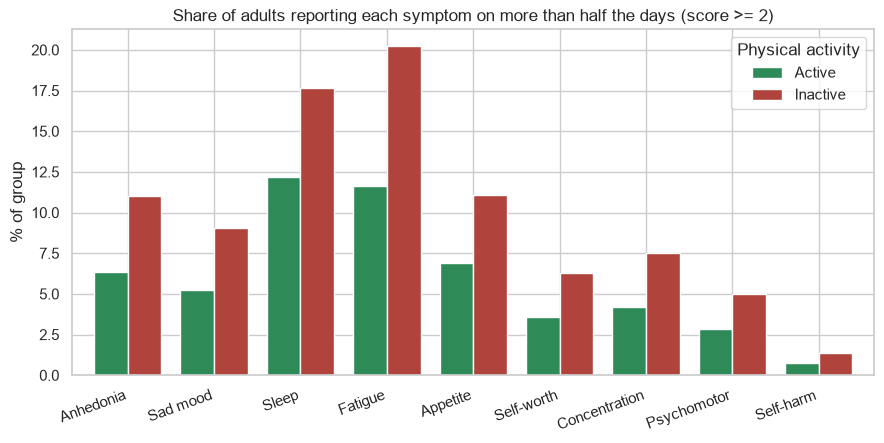

In [7]:
pre = (df.dropna(subset=['Active'])
         .groupby('Active')[ITEMS]
         .apply(lambda g: 100*(g>=2).mean()).T)
pre.index = SHORT
fig, ax = plt.subplots(figsize=(9,4.6))
pre.loc[:, ['Active','Inactive']].plot.bar(ax=ax, color=['#2e8b57','#b0443c'], width=.78)
ax.set_title('Share of adults reporting each symptom on more than half the days (score >= 2)')
ax.set_ylabel('% of group'); ax.set_xlabel('')
plt.setp(ax.get_xticklabels(), rotation=20, ha='right')
ax.legend(title='Physical activity')
fig.tight_layout(); fig.savefig(os.path.join(FIG,'fig01_symptom_prevalence_by_activity.png'), dpi=160); plt.show()

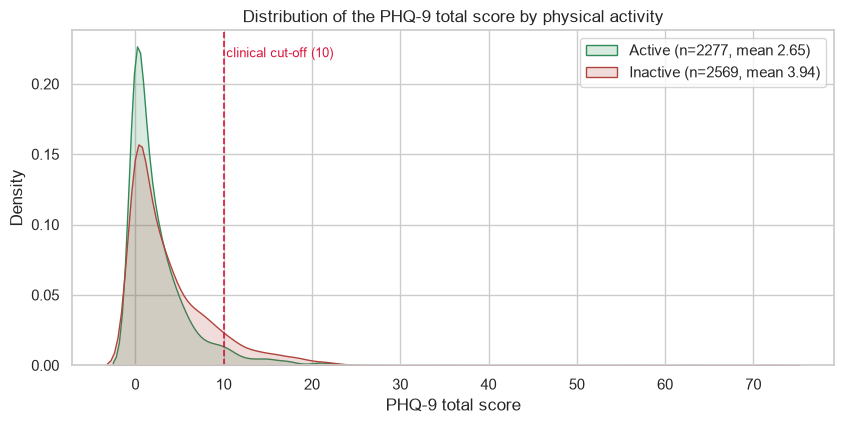

In [8]:
fig, ax = plt.subplots(figsize=(8.6,4.4))
for g, c in [('Active','#2e8b57'), ('Inactive','#b0443c')]:
    sub = df.loc[df['Active']==g,'PHQ9_total'].dropna()
    sns.kdeplot(sub, ax=ax, color=c, fill=True, alpha=.18, label='%s (n=%d, mean %.2f)' % (g, len(sub), sub.mean()))
ax.axvline(10, color='crimson', ls='--', lw=1.2)
ax.text(10.3, ax.get_ylim()[1]*.92, 'clinical cut-off (10)', color='crimson', fontsize=9)
ax.set_title('Distribution of the PHQ-9 total score by physical activity')
ax.set_xlabel('PHQ-9 total score'); ax.legend()
fig.tight_layout(); fig.savefig(os.path.join(FIG,'fig02_phq9_distribution.png'), dpi=160); plt.show()

/var/folders/68/2mlcq61s21z1vyg5z__f9_8r0000gn/T/ipykernel_30088/706363280.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Active', y='PHQ9_total', data=df.dropna(subset=['Active','PHQ9_total']),
/var/folders/68/2mlcq61s21z1vyg5z__f9_8r0000gn/T/ipykernel_30088/706363280.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Sex', y='PHQ9_total', data=df.dropna(subset=['PHQ9_total']),


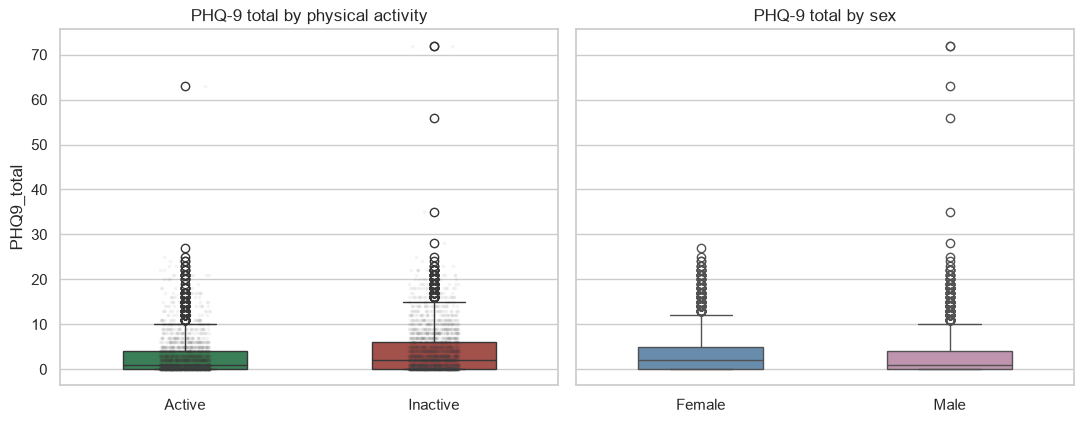

In [9]:
fig, axes = plt.subplots(1,2, figsize=(11,4.4), sharey=True)
sns.boxplot(x='Active', y='PHQ9_total', data=df.dropna(subset=['Active','PHQ9_total']),
            ax=axes[0], palette=['#2e8b57','#b0443c'], width=.5)
sns.stripplot(x='Active', y='PHQ9_total', data=df.dropna(subset=['Active','PHQ9_total']),
              ax=axes[0], alpha=.06, size=2.5, color='.25')
axes[0].set_title('PHQ-9 total by physical activity'); axes[0].set_xlabel('')
sns.boxplot(x='Sex', y='PHQ9_total', data=df.dropna(subset=['PHQ9_total']),
            ax=axes[1], palette=['#5b8db8','#c58db0'], width=.5)
axes[1].set_title('PHQ-9 total by sex'); axes[1].set_xlabel('')
fig.tight_layout(); fig.savefig(os.path.join(FIG,'fig03_box_activity_sex.png'), dpi=160); plt.show()

## 5. Exploratory and analysis figures (2 of 3)

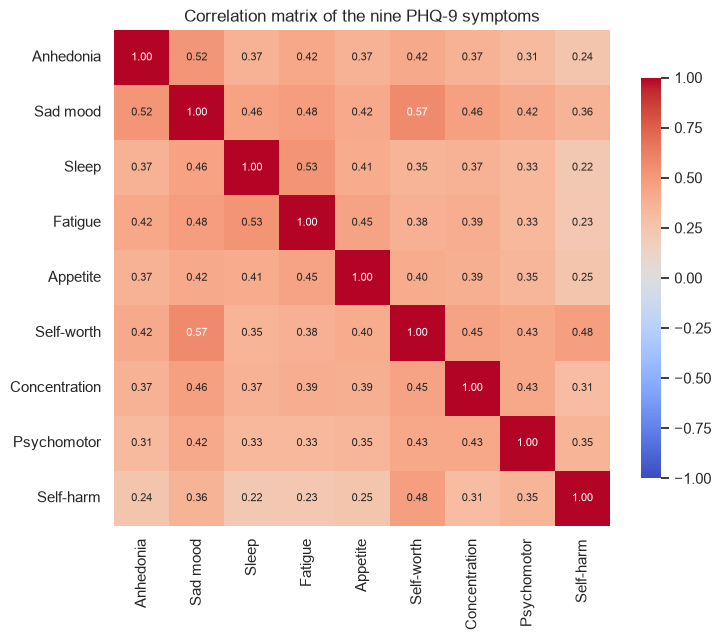

In [10]:
corr = df[ITEMS].corr()
corr.index = SHORT; corr.columns = SHORT
fig, ax = plt.subplots(figsize=(7.6,6.4))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={'shrink':.8}, annot_kws={'size':8})
ax.set_title('Correlation matrix of the nine PHQ-9 symptoms')
fig.tight_layout(); fig.savefig(os.path.join(FIG,'fig04_correlation_heatmap.png'), dpi=160); plt.show()

**Figure 5** — prevalence of clinically relevant depression (PHQ-9 ≥ 10) by activity with 95% Wilson
confidence intervals, with the chi-square test; **Figure 6** — dose–response across the four activity
levels (none / moderate only / vigorous only / both).

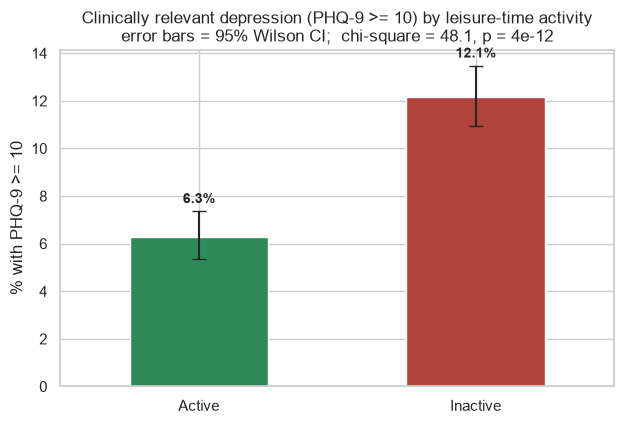

,depressed %,lo95,hi95,n
group,,,,
Active,6.28,5.36,7.35,2277
Inactive,12.14,10.94,13.46,2569


In [11]:
def wilson(p, n, z=1.96):
    den = 1 + z**2/n
    c   = (p + z**2/(2*n))/den
    hw  = z*np.sqrt(p*(1-p)/n + z**2/(4*n**2))/den
    return c-hw, c+hw

prev = (df.dropna(subset=['Active']).groupby('Active')['Depressed']
          .agg(['mean','count']))
rows = []
for g in ['Active','Inactive']:
    p, n = float(prev.loc[g,'mean']), int(prev.loc[g,'count'])
    lo, hi = wilson(p, n)
    rows.append((g, 100*p, 100*lo, 100*hi, n))
prev_tbl = pd.DataFrame(rows, columns=['group','depressed %','lo95','hi95','n']).set_index('group')

ct = pd.crosstab(df['Active'], df['Depressed'])
chi2, pchi, dof, _ = stats.chi2_contingency(ct)
S['dep_active_pct'], S['dep_inactive_pct'] = float(prev_tbl.loc['Active','depressed %']), float(prev_tbl.loc['Inactive','depressed %'])
S['chi2'], S['p_chi'], S['dof'] = round(float(chi2),2), float(pchi), int(dof)

fig, ax = plt.subplots(figsize=(6.4,4.4))
yerr = [(prev_tbl['depressed %']-prev_tbl['lo95']), (prev_tbl['hi95']-prev_tbl['depressed %'])]
prev_tbl['depressed %'].plot.bar(ax=ax, color=['#2e8b57','#b0443c'], width=.5,
                                 yerr=list(np.vstack(yerr)), capsize=5, rot=0)
for i,(g,r) in enumerate(prev_tbl.iterrows()):
    ax.text(i, r['hi95']+0.35, "%.1f%%" % r['depressed %'], ha='center', fontsize=10, fontweight='bold')
ax.set_title('Clinically relevant depression (PHQ-9 >= 10) by leisure-time activity\n'
             'error bars = 95%% Wilson CI;  chi-square = %.1f, p = %.2g' % (chi2, pchi))
ax.set_ylabel('% with PHQ-9 >= 10'); ax.set_xlabel('')
fig.tight_layout(); fig.savefig(os.path.join(FIG,'fig05_depression_prevalence_ci.png'), dpi=160); plt.show()
prev_tbl.round(2)

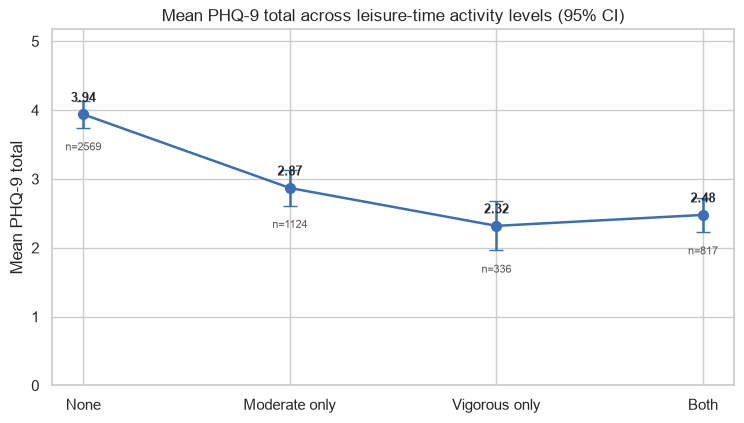

,mean,sem,count,lo95,hi95
PA_level,,,,,
None,3.94,0.10,2569,3.74,4.14
Moderate only,2.87,0.13,1124,2.61,3.12
Vigorous only,2.32,0.18,336,1.96,2.68
Both,2.48,0.13,817,2.23,2.73


In [12]:
dose = (df.dropna(subset=['PA_level','PHQ9_total'])
          .groupby('PA_level')['PHQ9_total']
          .agg(['mean','sem','count'])
          .reindex(['None','Moderate only','Vigorous only','Both']))
dose['lo95'], dose['hi95'] = dose['mean']-1.96*dose['sem'], dose['mean']+1.96*dose['sem']
S['dose'] = {k: [round(float(r['mean']),2), int(r['count'])] for k,r in dose.iterrows()}

fig, ax = plt.subplots(figsize=(7.6,4.4))
ax.errorbar(range(len(dose)), dose['mean'],
            yerr=[dose['mean']-dose['lo95'], dose['hi95']-dose['mean']],
            fmt='o-', color='#3b6fb5', capsize=5, lw=1.8, ms=7)
for i,(m,n) in enumerate(zip(dose['mean'], dose['count'])):
    ax.annotate('%.2f' % m, (i, m), textcoords='offset points', xytext=(0,9),
                ha='center', fontsize=9, fontweight='bold')
    ax.annotate('n=%d' % n, (i, dose['lo95'].iloc[i]), textcoords='offset points',
                xytext=(0,-16), ha='center', fontsize=8, color='.35')
ax.set_xticks(range(len(dose))); ax.set_xticklabels(dose.index)
ax.set_title('Mean PHQ-9 total across leisure-time activity levels (95% CI)')
ax.set_ylabel('Mean PHQ-9 total'); ax.set_ylim(0, max(dose['hi95'])*1.25)
fig.tight_layout(); fig.savefig(os.path.join(FIG,'fig06_dose_response.png'), dpi=160); plt.show()
dose.round(2)

**Figure 11** — the physical-activity paradox. Mean PHQ-9 total in the 2 x 2 of leisure-time activity x
occupational activity. Epidemiology consistently finds that *leisure-time* activity tracks better health
while *occupational* activity (largely manual labour) does not; the figure checks whether NHANES shows the
same reversal.

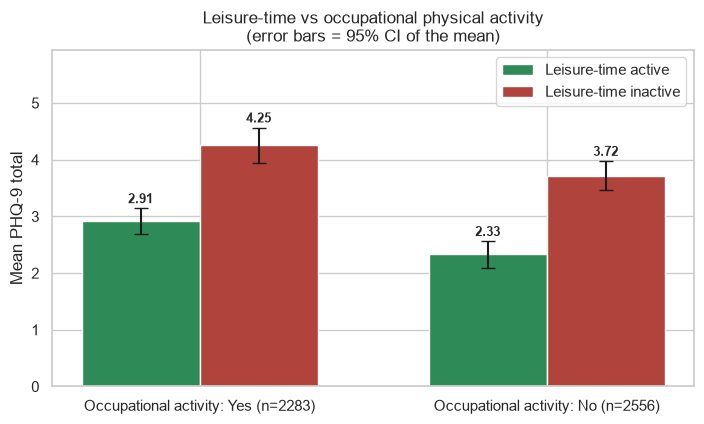

mean   sem  count  lo95  hi95
Work Active                                 
No   Active    2.33  0.12   1040  2.10  2.56
     Inactive  3.72  0.13   1516  3.46  3.98
Yes  Active    2.91  0.12   1234  2.69  3.14
     Inactive  4.25  0.16   1049  3.94  4.57

In [13]:
par = (df.dropna(subset=['Active','Work','PHQ9_total'])
         .groupby(['Work','Active'])['PHQ9_total']
         .agg(['mean','sem','count']))
par['lo95'], par['hi95'] = par['mean']-1.96*par['sem'], par['mean']+1.96*par['sem']
S['paradox'] = {'%s|%s' % (w,a): [round(float(r['mean']),2), int(r['count'])]
                for (w,a),r in par.iterrows()}
fig, ax = plt.subplots(figsize=(7.2,4.4))
w = 0.34
for j,(a,c) in enumerate([('Active','#2e8b57'), ('Inactive','#b0443c')]):
    xs = np.arange(2) + (j-0.5)*w
    ys = [par.loc[(wk,a),'mean'] for wk in ['Yes','No']]
    es = [1.96*par.loc[(wk,a),'sem'] for wk in ['Yes','No']]
    ax.bar(xs, ys, width=w, color=c, yerr=es, capsize=5, label='Leisure-time %s' % a.lower())
    for x, v, hi in zip(xs, ys, [par.loc[(wk, a), 'hi95'] for wk in ['Yes', 'No']]):
        ax.text(x, hi + 0.09, '%.2f' % v, ha='center', fontsize=9, fontweight='bold')
ax.set_xticks(np.arange(2))
ax.set_xticklabels(['Occupational activity: Yes (n=%d)' % int(par.loc[('Yes','Active'),'count']+par.loc[('Yes','Inactive'),'count']),
                    'Occupational activity: No (n=%d)'  % int(par.loc[('No','Active'),'count']+par.loc[('No','Inactive'),'count'])])
ax.set_ylabel('Mean PHQ-9 total'); ax.set_ylim(0, max(par['hi95'])*1.3)
ax.set_title('Leisure-time vs occupational physical activity\n(error bars = 95% CI of the mean)')
ax.legend()
fig.tight_layout(); fig.savefig(os.path.join(FIG,'fig11_activity_paradox.png'), dpi=160); plt.show()
par.round(2)

## 6. Adjusted model — logistic regression and forest plot (**Figure 7**)

In [14]:
mdl = df.dropna(subset=['Depressed','RIDAGEYR','BMXBMI','Active','Work']).copy()
mdl['female']   = (mdl['Sex']=='Female').astype(int)
mdl['active']   = (mdl['Active']=='Active').astype(int)
mdl['work_act'] = (mdl['Work']=='Yes').astype(int)
X = sm.add_constant(mdl[['RIDAGEYR','female','BMXBMI','active','work_act']]
                    .rename(columns={'RIDAGEYR':'age (per year)',
                                     'active':'leisure-time activity',
                                     'work_act':'occupational activity'}))
logit = sm.Logit(mdl['Depressed'], X).fit(disp=0)
OR = pd.DataFrame({'OR': np.exp(logit.params), 'lo': np.exp(logit.conf_int()[0]),
                   'hi': np.exp(logit.conf_int()[1]), 'p': logit.pvalues}).drop(index='const')
S['or'] = {k: [round(float(r.OR),2), round(float(r.lo),2), round(float(r.hi),2), float(r.p)] for k,r in OR.iterrows()}
S['or_n'], S['or_r2'] = int(len(mdl)), round(float(logit.prsquared),3)
print('n = %d   pseudo-R2 = %.3f' % (S['or_n'], S['or_r2']))
OR.round(3)

n = 4788   pseudo-R2 = 0.026


,OR,lo,hi,p
age (per year),0.999,0.993,1.005,0.692
female,1.406,1.149,1.722,0.001
BMXBMI,1.018,1.006,1.031,0.003
leisure-time activity,0.485,0.391,0.601,0.000
occupational activity,1.345,1.098,1.646,0.004


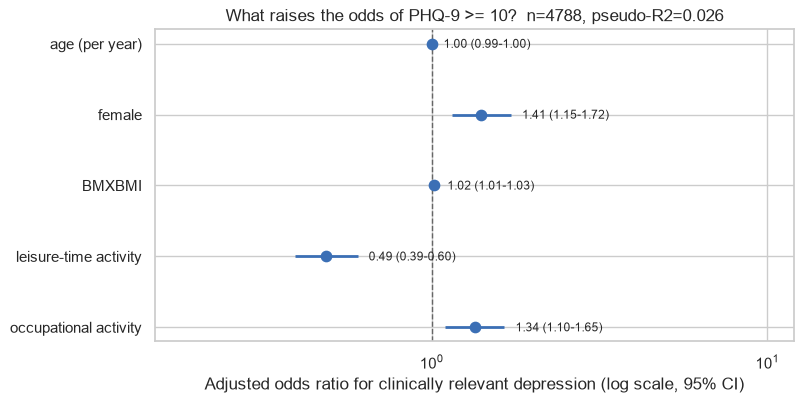

In [15]:
fig, ax = plt.subplots(figsize=(8.2,4.2))
y = np.arange(len(OR))[::-1]
ax.axvline(1, color='.4', ls='--', lw=1)
ax.hlines(y, OR['lo'], OR['hi'], color='#3b6fb5', lw=2)
ax.scatter(OR['OR'], y, s=55, color='#3b6fb5', zorder=3)
for yi,(k,r) in zip(y, OR.iterrows()):
    ax.annotate('%.2f (%.2f-%.2f)' % (r.OR, r.lo, r.hi), (r.hi, yi),
                textcoords='offset points', xytext=(8,-3), fontsize=8.5)
ax.set_yticks(y); ax.set_yticklabels(OR.index)
ax.set_xscale('log'); ax.set_xlim(0.15, 12)
ax.set_xlabel('Adjusted odds ratio for clinically relevant depression (log scale, 95% CI)')
ax.set_title('What raises the odds of PHQ-9 >= 10?  n=%d, pseudo-R2=%.3f' % (S['or_n'], S['or_r2']))
fig.tight_layout(); fig.savefig(os.path.join(FIG,'fig07_or_forest.png'), dpi=160); plt.show()

## 7. Age-stratified check (**Figure 8**)
Mean PHQ-9 total by age band and activity, to see whether the activity gap is concentrated in any age
group rather than being uniform.

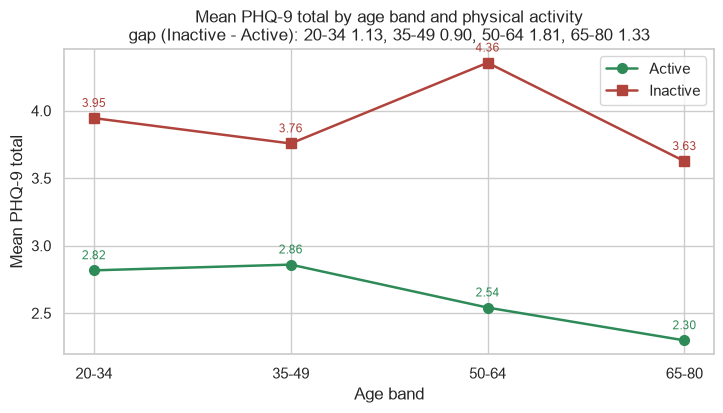

Active,Active,Inactive
AgeBand,,
20-34,2.82,3.95
35-49,2.86,3.76
50-64,2.54,4.36
65-80,2.30,3.63


In [16]:
ab = (df.dropna(subset=['Active','PHQ9_total'])
        .groupby(['AgeBand','Active'])['PHQ9_total'].mean().unstack())
S['ageband'] = {str(k): {g: round(float(v),2) for g,v in row.items()} for k,row in ab.iterrows()}
fig, ax = plt.subplots(figsize=(7.4,4.3))
for g,c,mk in [('Active','#2e8b57','o'), ('Inactive','#b0443c','s')]:
    ax.plot(ab.index.astype(str), ab[g], marker=mk, color=c, lw=1.8, ms=7, label=g)
    for x,v in zip(ab.index.astype(str), ab[g]):
        ax.annotate('%.2f' % v, (x,v), textcoords='offset points', xytext=(0,8),
                    ha='center', fontsize=8.5, color=c)
gap = (ab['Inactive']-ab['Active'])
ax.set_title('Mean PHQ-9 total by age band and physical activity\n'
             'gap (Inactive - Active): ' + ', '.join('%s %.2f' % (i,g) for i,g in gap.items()))
ax.set_xlabel('Age band'); ax.set_ylabel('Mean PHQ-9 total'); ax.legend()
fig.tight_layout(); fig.savefig(os.path.join(FIG,'fig08_age_interaction.png'), dpi=160); plt.show()
ab.round(2)

## 8. Group comparisons (formal tests)
Chi-square test behind Figure 5; Welch *t*-tests for the PHQ-9 total by activity and by sex, with Cohen's *d*.

In [17]:
a = df.loc[df['Active']=='Active','PHQ9_total'].dropna()
i = df.loc[df['Active']=='Inactive','PHQ9_total'].dropna()
t, pt = stats.ttest_ind(a, i, equal_var=False)
sp = np.sqrt(((len(a)-1)*a.var(ddof=1)+(len(i)-1)*i.var(ddof=1))/(len(a)+len(i)-2))
dcohen = (i.mean()-a.mean())/sp
S.update(mean_act=round(float(a.mean()),2), mean_inact=round(float(i.mean()),2),
         t=round(float(t),2), p_t=float(pt), d=round(float(dcohen),2))
print('PHQ-9 total  Active %.2f (n=%d) vs Inactive %.2f (n=%d):  t=%.2f, p=%.3g, Cohen d=%.2f'
      % (a.mean(), len(a), i.mean(), len(i), t, pt, dcohen))
m = df.loc[df['Sex']=='Male','PHQ9_total'].dropna(); f = df.loc[df['Sex']=='Female','PHQ9_total'].dropna()
t2, p2 = stats.ttest_ind(m, f, equal_var=False)
S.update(mean_male=round(float(m.mean()),2), mean_female=round(float(f.mean()),2),
         t_sex=round(float(t2),2), p_sex=float(p2))
print('PHQ-9 total  Male %.2f vs Female %.2f:  t=%.2f, p=%.3g' % (m.mean(), f.mean(), t2, p2))

PHQ-9 total  Active 2.65 (n=2277) vs Inactive 3.94 (n=2569):  t=-9.81, p=1.68e-22, Cohen d=0.28
PHQ-9 total  Male 2.94 vs Female 3.71:  t=-5.74, p=9.92e-09


## 9. Network analysis (**Figure 9**)
Gaussian partial-correlation network of the nine PHQ-9 symptoms: every edge is the association between two
symptoms with the other seven held constant. Green edges positive, red negative; node size encodes strength
centrality.

In [18]:
net_df = df[ITEMS].dropna()
S['net_n'] = int(len(net_df))
R = np.corrcoef(net_df.values.T)
Rinv = np.linalg.inv(R)
d = np.sqrt(np.diag(Rinv))
pc = -Rinv/np.outer(d,d); np.fill_diagonal(pc, 1.0)
pc = pd.DataFrame(pc, index=SHORT, columns=SHORT)

THRESH = 0.05
G = nx.Graph(); G.add_nodes_from(SHORT); edges = []
for a in range(len(SHORT)):
    for b in range(a+1, len(SHORT)):
        w = pc.iloc[a,b]
        if abs(w) > THRESH:
            G.add_edge(SHORT[a], SHORT[b], weight=abs(w), sign=np.sign(w))
            edges.append((SHORT[a], SHORT[b], round(float(w),3)))
S['n_edges'] = int(G.number_of_edges())
strength = pc.abs().sum()-1.0
S['strength'] = {k: round(float(v),2) for k,v in strength.sort_values(ascending=False).items()}
S['top_edges'] = sorted(edges, key=lambda e: -abs(e[2]))[:6]
print('complete cases: %d | edges kept (|partial r| > %.2f): %d of 36'
      % (len(net_df), THRESH, G.number_of_edges()))
centr = pd.DataFrame({'strength': strength.round(3),
                      'expected_influence': (pc.sum()-1).round(3)}).sort_values('strength', ascending=False)
centr

complete cases: 4846 | edges kept (|partial r| > 0.05): 28 of 36


,strength,expected_influence
Sad mood,1.123,1.123
Self-worth,1.046,1.046
Fatigue,0.920,0.891
Concentration,0.818,0.818
Sleep,0.784,0.784
Appetite,0.754,0.754
Psychomotor,0.753,0.753
Anhedonia,0.734,0.716
Self-harm,0.596,0.548


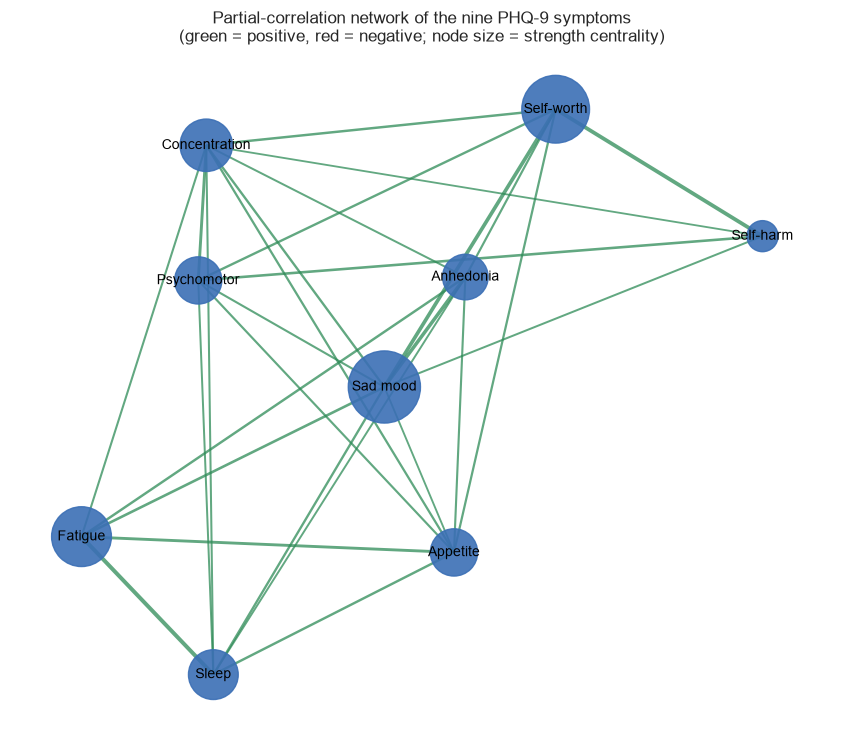

In [19]:
fig, ax = plt.subplots(figsize=(8.6,7.6))
pos = nx.spring_layout(G, seed=1, k=0.9)
ns = 500 + 2200*(strength-strength.min())/(strength.max()-strength.min())
ec = ['#2e8b57' if s>0 else '#c0392b' for _,_,s in G.edges(data='sign')]
ew = [1+6*w for _,_,w in G.edges(data='weight')]
nx.draw_networkx_edges(G, pos, edge_color=ec, width=ew, alpha=.75, ax=ax)
nx.draw_networkx_nodes(G, pos, node_size=ns, node_color='#3b6fb5', alpha=.9, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=10, font_color='black', ax=ax)
ax.set_title('Partial-correlation network of the nine PHQ-9 symptoms\n'
             '(green = positive, red = negative; node size = strength centrality)')
ax.axis('off'); fig.tight_layout()
fig.savefig(os.path.join(FIG,'fig09_symptom_network.png'), dpi=170); plt.show()

## 10. Network comparison — active vs inactive (**Figure 10**)
Global strength (sum of absolute edge weights) summarises how tightly the symptom system hangs together.
A permutation test (1,000 shuffles of group labels) assesses the difference.

Global strength  Active 7.59 (n=2277) vs Inactive 7.58 (n=2569)  |diff|=0.01  permutation p=0.986


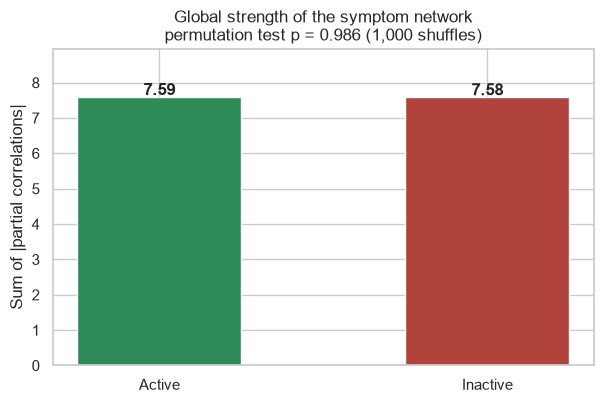

In [20]:
def global_strength(sub):
    R = np.corrcoef(sub.values.T); Ri = np.linalg.inv(R); dd = np.sqrt(np.diag(Ri))
    p = -Ri/np.outer(dd,dd); np.fill_diagonal(p,0)
    return float(np.abs(p).sum())

grp   = df.dropna(subset=['Active'])[ITEMS+['Active']]
act   = grp[grp['Active']=='Active'][ITEMS].dropna()
inact = grp[grp['Active']=='Inactive'][ITEMS].dropna()
gs_a, gs_i = global_strength(act), global_strength(inact)
obs = abs(gs_a-gs_i)
S.update(gs_active=round(gs_a,2), gs_inactive=round(gs_i,2),
         n_net_active=int(len(act)), n_net_inactive=int(len(inact)))

labels = np.array(['Active']*len(act)+['Inactive']*len(inact))
pool = pd.concat([act,inact], ignore_index=True).values
perm = []
for _ in range(1000):
    g = labels[rng.permutation(len(labels))]
    perm.append(abs(global_strength(pd.DataFrame(pool[g=='Active']))
                  - global_strength(pd.DataFrame(pool[g=='Inactive']))))
pval = (1+sum(1 for x in perm if x>=obs))/(1+len(perm))
S['perm_p'] = round(float(pval),3)
print('Global strength  Active %.2f (n=%d) vs Inactive %.2f (n=%d)  |diff|=%.2f  permutation p=%.3f'
      % (gs_a, len(act), gs_i, len(inact), obs, pval))

fig, ax = plt.subplots(figsize=(6.2,4.2))
bars = ax.bar(['Active','Inactive'], [gs_a, gs_i], color=['#2e8b57','#b0443c'], width=.5)
for b,v in zip(bars,[gs_a,gs_i]):
    ax.text(b.get_x()+b.get_width()/2, v+0.06, '%.2f' % v, ha='center', fontweight='bold')
ax.set_ylim(0, max(gs_a,gs_i)*1.18)
ax.set_title('Global strength of the symptom network\npermutation test p = %.3f (1,000 shuffles)' % pval)
ax.set_ylabel('Sum of |partial correlations|')
fig.tight_layout(); fig.savefig(os.path.join(FIG,'fig10_global_strength.png'), dpi=160); plt.show()

## 11. Figure-to-question checklist
Every figure is mapped to the part of the research question it answers — this is the checklist referred to
in the proposal's *Criteria for Success*.

In [21]:
checklist = pd.DataFrame([
 ['Fig 1','Symptom prevalence by activity','Which symptoms differ most between leisure-time active and inactive adults'],
 ['Fig 2','PHQ-9 distribution by activity','Is the whole severity distribution shifted, or only the tail?'],
 ['Fig 3','Score by activity and by sex','Is the activity gap confounded with sex differences?'],
 ['Fig 4','Item correlation heatmap','Are the symptoms correlated at all (the premise of a network model)?'],
 ['Fig 5','Depression prevalence with 95% CI','Is clinically relevant depression less common among leisure-time active adults?'],
 ['Fig 6','Dose-response across activity levels','Does more leisure-time activity go with a lower symptom level?'],
 ['Fig 7','Adjusted odds-ratio forest plot','Is the activity association independent of age, sex and BMI?'],
 ['Fig 8','Age-stratified means','Is the gap uniform across age bands?'],
 ['Fig 9','Partial-correlation network','Which symptoms are the hubs of the system?'],
 ['Fig 10','Global-strength comparison','Is the network wired differently in leisure-time active adults?'],
 ['Fig 11','Leisure-time vs occupational activity','Is the activity association reversed for work activity (the paradox)?'],
], columns=['Figure','What it shows','Part of the research question'])
checklist

,Figure,What it shows,Part of the research question
0,Fig 1,Symptom prevalence by activity,Which symptoms differ most between leisure-tim...
1,Fig 2,PHQ-9 distribution by activity,"Is the whole severity distribution shifted, or..."
2,Fig 3,Score by activity and by sex,Is the activity gap confounded with sex differ...
3,Fig 4,Item correlation heatmap,Are the symptoms correlated at all (the premis...
4,Fig 5,Depression prevalence with 95% CI,Is clinically relevant depression less common ...
5,Fig 6,Dose-response across activity levels,Does more leisure-time activity go with a lowe...
6,Fig 7,Adjusted odds-ratio forest plot,Is the activity association independent of age...
7,Fig 8,Age-stratified means,Is the gap uniform across age bands?
8,Fig 9,Partial-correlation network,Which symptoms are the hubs of the system?
9,Fig 10,Global-strength comparison,Is the network wired differently in leisure-ti...


## 12. Persist every number quoted in the proposal

In [22]:
S['symptom_table'] = sym.to_dict('records')
S['severity_order'] = list(sev.index)
with open('stats_a02.json','w') as f:
    json.dump(S, f, indent=1, default=str)
print('stats_a02.json written:', len(S), 'entries')

stats_a02.json written: 42 entries
